### What is Cache-Augmented Generation (CAG)?
CAG is a retrieval-free approach that bypasses the usual step of querying external knowledge sources at inference time. Instead, it preloads relevant documents into the LLM's extended context window, precomputes the model’s key‑value (KV) cache, and reuses this during inference—so the model can generate responses without additional retrieval steps 

In [1]:
import os
from dotenv import load_dotenv
load_dotenv()
os.environ["GROQ_API_KEY"]= os.getenv("GROQ_API_KEY")

from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001FD7C597620>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001FD7C74C440>, model_name='openai/gpt-oss-120b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'))

In [2]:
### Cache variable
Model_Cache={}

In [3]:
import time

def cache_model(query):
    start_time=time.time()
    if Model_Cache.get(query):
        print("**Cache Hit**")
        end_time=time.time()
        elapsed_time=end_time-start_time
        print(f"EXECUTION TIME: {elapsed_time:.2f} seconds")
        return Model_Cache.get(query)
    else:
        print("***CACHE MISS - EXECUTING MODEL***")
        start_time= time.time()
        response = llm.invoke(query)
        end_time = time.time()
        elapsed = end_time - start_time
        print(f"EXECUTION TIME: {elapsed:.2f} seconds")
        Model_Cache[query] = response
        return response

In [4]:
response = cache_model("hi")
response

***CACHE MISS - EXECUTING MODEL***
EXECUTION TIME: 0.92 seconds


AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "hi". We need to respond appropriately. It\'s a simple greeting. Should respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 72, 'total_tokens': 112, 'completion_time': 0.082573467, 'completion_tokens_details': {'reasoning_tokens': 22}, 'prompt_time': 0.003326957, 'prompt_tokens_details': None, 'queue_time': 0.364857594, 'total_time': 0.085900424}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_19b184c447', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1a4b3-748a-72c5-80a6-21179aa1d759-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 40, 'total_tokens': 112, 'output_token_details': {'reasoning': 22}})

In [5]:
Model_Cache

{'hi': AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "hi". We need to respond appropriately. It\'s a simple greeting. Should respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 72, 'total_tokens': 112, 'completion_time': 0.082573467, 'completion_tokens_details': {'reasoning_tokens': 22}, 'prompt_time': 0.003326957, 'prompt_tokens_details': None, 'queue_time': 0.364857594, 'total_time': 0.085900424}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_19b184c447', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1a4b3-748a-72c5-80a6-21179aa1d759-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 40, 'total_tokens': 112, 'output_token_details': {'reasoning': 22}})}

In [6]:
response=cache_model("hi")
response

**Cache Hit**
EXECUTION TIME: 0.00 seconds


AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "hi". We need to respond appropriately. It\'s a simple greeting. Should respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 72, 'total_tokens': 112, 'completion_time': 0.082573467, 'completion_tokens_details': {'reasoning_tokens': 22}, 'prompt_time': 0.003326957, 'prompt_tokens_details': None, 'queue_time': 0.364857594, 'total_time': 0.085900424}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_19b184c447', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1a4b3-748a-72c5-80a6-21179aa1d759-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 40, 'total_tokens': 112, 'output_token_details': {'reasoning': 22}})

In [7]:
query="can you give me 500 words on langgraph?"
response =cache_model(query)
print(response)

***CACHE MISS - EXECUTING MODEL***
EXECUTION TIME: 4.02 seconds
content='**LangGraph: A 500‑Word Overview**\n\nLangGraph is an open‑source Python library that makes it easy to construct, visualize, and execute complex, state‑driven workflows for large language model (LLM) applications. Built on top of LangChain, LangGraph adds a graph‑oriented abstraction layer that lets developers think of an LLM‑powered system as a network of interconnected “nodes” (functions, prompts, or agents) and “edges” (state transitions). This paradigm shift—from linear chains of calls to dynamic, branching graphs—enables more expressive, maintainable, and resilient AI applications.\n\n---\n\n### Core Concepts\n\n1. **Nodes**  \n   A node encapsulates a single unit of computation. It can be a simple prompt template, a custom Python function, an external API call, or an entire LangChain agent. Nodes receive a **state** dictionary, perform their logic, and return an updated state. Because the state is a mutable 

In [8]:
query="can you give me 500 words on langgraph?"
response =cache_model(query)
print(response)

**Cache Hit**
EXECUTION TIME: 0.00 seconds
content='**LangGraph: A 500‑Word Overview**\n\nLangGraph is an open‑source Python library that makes it easy to construct, visualize, and execute complex, state‑driven workflows for large language model (LLM) applications. Built on top of LangChain, LangGraph adds a graph‑oriented abstraction layer that lets developers think of an LLM‑powered system as a network of interconnected “nodes” (functions, prompts, or agents) and “edges” (state transitions). This paradigm shift—from linear chains of calls to dynamic, branching graphs—enables more expressive, maintainable, and resilient AI applications.\n\n---\n\n### Core Concepts\n\n1. **Nodes**  \n   A node encapsulates a single unit of computation. It can be a simple prompt template, a custom Python function, an external API call, or an entire LangChain agent. Nodes receive a **state** dictionary, perform their logic, and return an updated state. Because the state is a mutable mapping, any piece of

In [9]:
query="give me 500 words on langgraph?"
response =cache_model(query)
print(response)

***CACHE MISS - EXECUTING MODEL***
EXECUTION TIME: 3.75 seconds
content='**LangGraph: A 500‑Word Overview**\n\nLangGraph is an open‑source Python framework that extends the capabilities of large language model (LLM) orchestration libraries—most notably LangChain—by introducing a graph‑centric abstraction for building, visualizing, and managing complex LLM‑driven workflows. While LangChain popularized the notion of “chains” (linear sequences of prompts, tools, and memory), LangGraph treats every component of an LLM application as a node in a directed graph, allowing developers to model branching logic, loops, conditional execution, and parallelism with the same ease that they write ordinary Python functions.\n\n---\n\n### Core Concepts\n\n1. **Nodes** – The atomic units of computation. A node can be a prompt template, a tool call (e.g., a database query, an API request), a memory retrieval, or any custom Python callable. Nodes expose a uniform `run(input)` interface, making them interch

### Advanced CAG

In [11]:
from __future__ import annotations
from typing import TypedDict, List, Optional
import time

## -- Lang
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver

from langchain_core.documents import Document
from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings

## FAISS
import faiss
from langchain_community.vectorstores import FAISS
from langchain_community.docstore.in_memory import InMemoryDocstore

In [12]:
# ================= CONFIG =================
EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"  # 384-dim
VECTOR_DIM = 384

LLM_MODEL = "openai/gpt-oss-120b"
LLM_TEMPERATURE = 0

RETRIEVE_TOP_K = 4
CACHE_TOP_K = 3

CACHE_DISTANCE_THRESHOLD = 0.45

# Optional TTL for cache entries (seconds). 0 = disabled.
CACHE_TTL_SEC = 0



In [13]:
# ================= STATE ==================
class RAGState(TypedDict):
    question: str
    normalized_question: str
    context_docs: List[Document]
    answer: Optional[str]
    citations: List[str]
    cache_hit: bool

In [14]:
# ============== GLOBALS ===================
from langchain_huggingface import HuggingFaceEmbeddings
EMBED = HuggingFaceEmbeddings(model_name=EMBED_MODEL)

d:\Mission Project\AgenticAI\agc\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3835.65it/s]


In [15]:
# ----- QA CACHE (EMPTY, SAFE INIT) -----
qa_index = faiss.IndexFlatL2(VECTOR_DIM)  # Distance; lower is better
QA_CACHE = FAISS(
    embedding_function=EMBED,
    index = qa_index,
    docstore=InMemoryDocstore({}),
    index_to_docstore_id={}
)

In [16]:
QA_CACHE

In [17]:
# ----- RAG STORE (demo only) -----
RAG_STORE = FAISS.from_texts(
    texts=[
        "LangGraph lets you compose stateful LLM workflows as graphs.",
        "In LangGraph, nodes can be cached; node caching memoizes outputs keyed by inputs for a TTL.",
        "Retrieval-Augmented Generation (RAG) retrieves external context and injects it into prompts.",
        "Semantic caching reuses prior answers when new questions are semantically similar."
    ],
    embedding=EMBED,
)

In [19]:
LLM = ChatGroq(model=LLM_MODEL, temperature=LLM_TEMPERATURE)

In [20]:
LLM

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001FDA048AD50>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001FDA048B750>, model_name='openai/gpt-oss-120b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'))

In [21]:
# ================ NODES ===================
def normalize_query(state: RAGState) -> RAGState:
    q = (state["question"] or "").strip()
    state["normalized_question"] = q.lower()
    return state

def semantic_cache_lookup(state: RAGState) -> RAGState:
    q = state["normalized_question"]
    state["cache_hit"] = False # Default

    if not q:
        return state
    
    # ✅ Guard: FAISS crashes if ntotal == 0 and you ask for k>0
    if getattr(QA_CACHE, "index", None) is None or QA_CACHE.index.ntotal == 0:
        return state

    # For FAISS L2 wrapper, this returns (Document, distance) with lower=better
    hits = QA_CACHE.similarity_search_with_score(q, k=CACHE_TOP_K)
    if not hits:
        return state

    best_doc, dist = hits[0]

    # Optional TTL
    if CACHE_TTL_SEC > 0:
        ts = best_doc.metadata.get("ts")
        if ts is None or (time.time() - float(ts)) > CACHE_TTL_SEC:
            return state

    # L2 distance gate (lower = more similar)
    if dist <= CACHE_DISTANCE_THRESHOLD:
        cached_answer = best_doc.metadata.get("answer")
        if cached_answer:
            state["answer"] = cached_answer
            state["citations"] = ["(cache)"]
            state["cache_hit"] = True
    return state


def respond_from_cache(state: RAGState) -> RAGState:
    return state

def retrieve(state: RAGState) -> RAGState:
    q = state["normalized_question"]
    docs = RAG_STORE.similarity_search(q, k=RETRIEVE_TOP_K)
    state["context_docs"] = docs
    return state


def generate(state: RAGState) -> RAGState:
    q = state["question"]
    docs = state.get("context_docs", [])
    ctx = "\n\n".join([f"[doc-{i}] {d.page_content}" for i, d in enumerate(docs, start=1)])

    system = (
        "You are a precise RAG assistant. Use the context when helpful. "
        "Cite with [doc-i] markers if you use a fact from the context."
    )
    user = f"Question: {q}\n\nContext:\n{ctx}\n\nWrite a concise answer with citations."

    resp = LLM.invoke([{"role": "system", "content": system},
                       {"role": "user", "content": user}])
    state["answer"] = resp.content
    state["citations"] = [f"[doc-{i}]" for i in range(1, len(docs) + 1)]
    return state

def cache_write(state: RAGState) -> RAGState:
    q = state["normalized_question"]
    a = state.get("answer")
    if not q or not a:
        return state

    QA_CACHE.add_texts(
        texts=[q],
        metadatas=[{
            "answer": a,
            "ts": time.time(),
        }]
    )
    return state

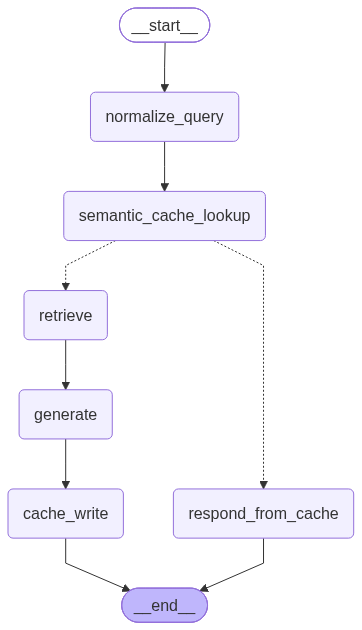

In [22]:
# ============== GRAPH WIRING ==============
graph = StateGraph(RAGState)

graph.add_node("normalize_query", normalize_query)
graph.add_node("semantic_cache_lookup", semantic_cache_lookup)
graph.add_node("respond_from_cache", respond_from_cache)
graph.add_node("retrieve", retrieve)
graph.add_node("generate", generate)
graph.add_node("cache_write", cache_write)

graph.set_entry_point("normalize_query")
graph.add_edge("normalize_query","semantic_cache_lookup")

def _branch(state: RAGState) -> str:
    return "respond_from_cache" if state.get("cache_hit") else "retrieve"

graph.add_conditional_edges(
    "semantic_cache_lookup",
    _branch,
    {
        "respond_from_cache": "respond_from_cache",
        "retrieve": "retrieve"
    }
)

graph.add_edge("respond_from_cache", END)
graph.add_edge("retrieve", "generate")
graph.add_edge("generate", "cache_write")
graph.add_edge("cache_write", END)

memory = MemorySaver()
app = graph.compile(checkpointer=memory)
app

In [23]:
# ================= DEMO ===================
if __name__ == "__main__":
    thread_cfg = {"configurable": {"thread_id": "demo-user-1"}}

    q1 = "What is LangGraph ?"
    out1 = app.invoke({"question": q1, "context_docs": [], "citations": []}, thread_cfg)
    print("Answer:", out1["answer"])
    print("Citations:", out1.get("citations"))
    print("Cache hit?:", out1.get("cache_hit"))

Answer: LangGraph is a framework for building stateful LLM pipelines by wiring together modular “nodes” into a graph‑structured workflow. It lets you compose complex, state‑aware language‑model applications as directed graphs, and even supports features such as node‑level caching of outputs keyed by inputs [doc‑2][doc‑1].
Citations: ['[doc-1]', '[doc-2]', '[doc-3]', '[doc-4]']
Cache hit?: False


In [24]:
q1 = "Explain about LangGraph ?"
out1 = app.invoke({"question": q1, "context_docs": [], "citations": []}, thread_cfg)
print("Answer:", out1["answer"])
print("Citations:", out1.get("citations"))
print("Cache hit?:", out1.get("cache_hit"))

Answer: LangGraph is a framework for building stateful LLM pipelines by wiring together modular “nodes” into a graph‑structured workflow. It lets you compose complex, state‑aware language‑model applications as directed graphs, and even supports features such as node‑level caching of outputs keyed by inputs [doc‑2][doc‑1].
Citations: ['(cache)']
Cache hit?: True


In [25]:
q1 = "Explain about LangGraph agents ?"
out1 = app.invoke({"question": q1, "context_docs": [], "citations": []}, thread_cfg)
print("Answer:", out1["answer"])
print("Citations:", out1.get("citations"))
print("Cache hit?:", out1.get("cache_hit"))

Answer: LangGraph agents are LLM‑driven components built on the **LangGraph** framework, which lets you model a workflow as a directed graph of stateful nodes. Each node can hold and update a shared “state” (e.g., the current conversation, retrieved documents, or intermediate reasoning steps), and the graph’s edges dictate how control flows between them — effectively turning a multi‑step prompt chain into a reusable, composable agent [doc‑2].

Key features that make LangGraph agents powerful:

* **Stateful orchestration** – the agent’s graph maintains a mutable state that persists across turns, enabling context‑aware reasoning and memory without external bookkeeping.  
* **Node caching** – outputs of individual nodes can be memoized (keyed by their inputs) for a configurable time‑to‑live, so repeated sub‑tasks (like identical retrieval calls) are served instantly, reducing latency and cost [doc‑1].  
* **RAG integration** – because the graph can include retrieval nodes, agents can perf

In [26]:
q1 = "Explain about agents in Langgraph ?"
out1 = app.invoke({"question": q1, "context_docs": [], "citations": []}, thread_cfg)
print("Answer:", out1["answer"])
print("Citations:", out1.get("citations"))
print("Cache hit?:", out1.get("cache_hit"))

Answer: LangGraph agents are LLM‑driven components built on the **LangGraph** framework, which lets you model a workflow as a directed graph of stateful nodes. Each node can hold and update a shared “state” (e.g., the current conversation, retrieved documents, or intermediate reasoning steps), and the graph’s edges dictate how control flows between them — effectively turning a multi‑step prompt chain into a reusable, composable agent [doc‑2].

Key features that make LangGraph agents powerful:

* **Stateful orchestration** – the agent’s graph maintains a mutable state that persists across turns, enabling context‑aware reasoning and memory without external bookkeeping.  
* **Node caching** – outputs of individual nodes can be memoized (keyed by their inputs) for a configurable time‑to‑live, so repeated sub‑tasks (like identical retrieval calls) are served instantly, reducing latency and cost [doc‑1].  
* **RAG integration** – because the graph can include retrieval nodes, agents can perf